# Predicting Credit-Card Default: Traditional ML vs Deep Learning

**ALU Machine Learning Summative.** Binary classification on the *Default of Credit Card Clients* dataset
(Yeh & Lien, 2009; UCI Machine Learning Repository, 30,000 rows, 23 predictors).

| Resource | Link |
|---|---|
| GitHub repository | `<ADD LINK>` |
| Google Drive folder (raw data, model weights, W&B logs) | `<ADD LINK>` |
| Presentation video | `<ADD LINK>` |

**Problem.** Given six months of a cardholder's repayment status, billed amounts and payments, predict whether the
cardholder will miss the payment due in the following month (`default = 1`). Missing a defaulter is far more
expensive for a lender than declining a good customer, so beyond accuracy I evaluate ranking quality
(ROC-AUC, PR-AUC), threshold-dependent precision/recall, and expected cost.

**Notebook map.**
1. Setup and reproducibility
2. Data loading and exploratory analysis
3. Cleaning, feature engineering and the preprocessing pipeline
4. Experiment infrastructure (metrics, logging)
5. Traditional ML experiments (scikit-learn)
6. Deep learning experiments (TensorFlow / Keras with `tf.data`)
7. Model selection and final test evaluation
8. Learning curves, bias-variance, confusion matrices, ROC / PR
9. Error analysis, feature importance, cost-sensitive thresholds
10. Saving artefacts and conclusions

**Protocol.** One stratified 70/15/15 train/validation/test split (seed 42). All fitting, including every
preprocessing step, uses the training set only. Model and threshold selection use validation data only. The test set is
evaluated once, at the end, for the two selected models and the baseline.
Every experiment is logged to Weights & Biases in **offline mode**, and Keras runs also write TensorBoard logs.

## 1. Setup and reproducibility

The cell below installs only what is missing (`wandb`, `xlrd`). On Colab, TensorFlow and scikit-learn are
already present; locally use `pip install -r requirements.txt`. Set the environment variable `QUICK=1` for a fast
smoke test that shrinks every search and epoch budget (numbers from a quick run are not meaningful).

In [1]:
import os, sys, time, json, random, warnings, subprocess, importlib
warnings.filterwarnings("ignore")

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

ensure("wandb"); ensure("xlrd")

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ["WANDB_MODE"] = "offline"      # logs stay on disk; nothing is uploaded
os.environ["WANDB_SILENT"] = "true"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib, wandb
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, precision_recall_curve, roc_curve, confusion_matrix)
from sklearn.model_selection import (train_test_split, StratifiedKFold, RandomizedSearchCV, learning_curve)
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

SEED = 42
QUICK = os.environ.get("QUICK") == "1"

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()

set_seed(SEED)

ROOT = Path(".")
DATA_PATH = ROOT / "data" / "raw.csv"
FIG, MOD, RES, TB, WB = (ROOT / d for d in ["figures", "models", "results", "logs", "wandb_logs"])
for d in (FIG, MOD, RES, TB, WB, DATA_PATH.parent):
    d.mkdir(parents=True, exist_ok=True)

print({"tensorflow": tf.__version__, "keras": keras.__version__, "pandas": pd.__version__,
       "numpy": np.__version__, "QUICK": QUICK})

I0000 00:00:1792413462.764103     204 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792413481.787268     204 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


{'tensorflow': '2.21.0', 'keras': '3.15.1', 'pandas': '3.0.5', 'numpy': '2.5.3', 'QUICK': False}


In [2]:
# Plot style: validated categorical slots 1-3 (blue, orange, aqua) from the reference palette; muted ink for text.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "lines.linewidth": 2.0, "font.size": 9,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
MODEL_COLOURS = {"LR": BLUE, "ML": ORANGE, "DL": AQUA}

def savefig(fig, name):
    fig.savefig(FIG / name); plt.show()

## 2. Data loading and exploratory analysis

**Source.** UCI Machine Learning Repository, *Default of Credit Card Clients* (dataset 350), collected from a Taiwanese
card issuer between April and September 2005 (Yeh & Lien, 2009). It is an open, real-world, non-synthetic dataset
with 30,000 rows, above the 20,000-row threshold, and a binary target.

`load_raw()` reads `data/raw.csv` if present. Otherwise it downloads the UCI archive, parses the `.xls`
(header on the second row) and caches a CSV. The raw file is **not** committed to GitHub; it lives in the
shared Drive folder (zipped). If the download is blocked, place the CSV from Drive at `data/raw.csv`.

Column notes: `PAY_0`...`PAY_6` are repayment status codes for September back to April
(-1 paid duly, 0 revolving credit, 1..9 months of payment delay; -2 is undocumented and is commonly read as no consumption);
`BILL_AMT1..6` are billed amounts and `PAY_AMT1..6` are payments, in NT dollars. `PAY_0` is renamed `PAY_1` internally
for consistency.

In [3]:
UCI_URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
TARGET_RAW = "default payment next month"

def load_raw(path=DATA_PATH):
    if path.exists():
        df = pd.read_csv(path)
    else:
        import io, zipfile, urllib.request
        blob = urllib.request.urlopen(UCI_URL, timeout=60).read()
        z = zipfile.ZipFile(io.BytesIO(blob))
        xls = [n for n in z.namelist() if n.lower().endswith(".xls")][0]
        df = pd.read_excel(io.BytesIO(z.read(xls)), header=1)
        df.to_csv(path, index=False)
    assert len(df) >= 20_000, "dataset must have at least 20,000 rows"
    assert df[TARGET_RAW].nunique() >= 2
    return df

raw = load_raw()
print(raw.shape)
print("missing values:", int(raw.isna().sum().sum()),
      "| duplicate rows ignoring ID:", int(raw.duplicated(subset=raw.columns[1:]).sum()))
print(raw[TARGET_RAW].value_counts(normalize=True).rename("share").round(4).to_dict())
raw.head()

(30000, 25)
missing values: 0 | duplicate rows ignoring ID: 35
{0: 0.7788, 1: 0.2212}


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


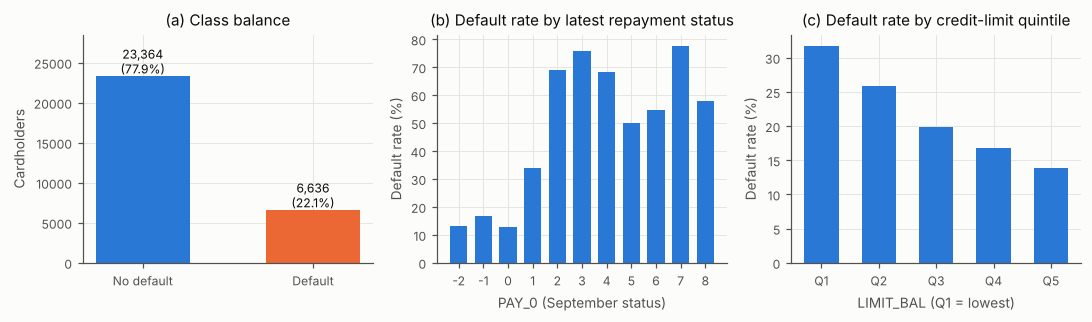

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3.0))
cls = raw[TARGET_RAW].value_counts().sort_index()
ax[0].bar(["No default", "Default"], cls.values, color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(cls.values):
    ax[0].text(i, v + 300, f"{v:,}\n({v/len(raw):.1%})", ha="center", fontsize=8, color=INK)
ax[0].set_ylim(0, cls.max() * 1.22); ax[0].set_title("(a) Class balance"); ax[0].set_ylabel("Cardholders")

g = raw.groupby("PAY_0")[TARGET_RAW].agg(["mean", "size"])
ax[1].bar(g.index.astype(str), g["mean"] * 100, color=BLUE, width=0.7)
ax[1].set_title("(b) Default rate by latest repayment status"); ax[1].set_xlabel("PAY_0 (September status)")
ax[1].set_ylabel("Default rate (%)")

q = pd.qcut(raw["LIMIT_BAL"], 5, duplicates="drop")
gl = raw.groupby(q, observed=True)[TARGET_RAW].mean() * 100
ax[2].bar(range(len(gl)), gl.values, color=BLUE, width=0.6)
ax[2].set_xticks(range(len(gl))); ax[2].set_xticklabels([f"Q{i+1}" for i in range(len(gl))])
ax[2].set_title("(c) Default rate by credit-limit quintile"); ax[2].set_xlabel("LIMIT_BAL (Q1 = lowest)")
ax[2].set_ylabel("Default rate (%)")
fig.tight_layout(); savefig(fig, "fig1_eda.png")

**Reading the figure.** The target is imbalanced (22.1% defaults), so a classifier that always predicts "no default" is 77.9% accurate. I therefore report ROC-AUC, PR-AUC (average precision) and threshold-based precision and recall rather than accuracy. Default risk is driven by recent repayment behaviour: customers who paid duly or used revolving credit (`PAY_0` <= 0) default 13-17% of the time, one month of delay raises this to 34%, and two or more months to roughly 70% (statuses of 5 or more have fewer than 30 customers each and are noisy). Lower credit limits are also riskier, about 32% in the lowest quintile against 14% in the highest. These patterns motivate the engineered delay and utilisation features.

## 3. Cleaning, feature engineering and the preprocessing pipeline

All transformations live in one scikit-learn `Pipeline` that accepts the raw columns, so the saved model can score a
new applicant directly. The stateless cleaning and feature-engineering function `prepare` is kept in `creditfeatures.py`
(next to the notebook in the repository) so that a saved pipeline can be unpickled in any environment; its source is printed below. Decisions and their rationale:

* **Undocumented category codes.** `EDUCATION` values 0, 5, 6 (345 rows) are merged into "others" (4); `MARRIAGE` 0
  (54 rows) is merged into "others" (3). Both are label-coding defects, not real categories.
* **Duplicates.** 35 rows duplicate another row on every predictor, but 86% of the affected rows have all-zero bills (dormant
  accounts) and they carry distinct IDs, so they are kept rather than removed on weak evidence.
* **Negative bills.** 1,930 customers have a negative `BILL_AMT` (a credit balance after overpayment). This is valid, so it is kept and
  flagged with an engineered indicator.
* **Heavy tails / outliers.** Monetary columns span several orders of magnitude (`BILL_AMT` up to 1.66 M). I apply a signed
  `log1p` transform and then standardise. No rows are dropped. Engineered ratios are winsorised by clipping.
* **Encoding.** `SEX`, `EDUCATION`, `MARRIAGE` are one-hot encoded. `PAY_*` are kept ordinal because delay length is ordered.
* **Scaling.** `StandardScaler` fitted on the training set only (needed for logistic regression, SVM and the neural networks;
  harmless for trees).

**Engineered features** (credit-risk ratios of the kind used in scorecards):
utilisation (bill / limit: mean, max, latest), bill trend, payment-to-previous-bill ratio (mean, min, latest), number of delayed months, maximum delay,
mean repayment status and a credit-balance flag. Experiments M1/M2 and M5/M4 and D2/D1 isolate their effect by comparing the `base` and `eng` feature sets.

In [5]:
from creditfeatures import PAY, BILL, PAYAMT, CAT, ENG, DEMOGRAPHIC, signed_log1p, prepare
import inspect
print(inspect.getsource(prepare))

def make_preprocessor(feature_set="eng", drop=()):
    # feature_set: 'base' (cleaned raw columns) or 'eng' (base + engineered). drop: columns to exclude.
    money = ["LIMIT_BAL"] + BILL + PAYAMT
    plain = ["AGE"] + PAY + (ENG if feature_set == "eng" else [])
    keep = lambda cols: [c for c in cols if c not in drop]
    ct = ColumnTransformer([
        ("money", Pipeline([("log", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                            ("scale", StandardScaler())]), keep(money)),
        ("plain", StandardScaler(), keep(plain)),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), keep(CAT)),
    ])
    return Pipeline([("prepare", FunctionTransformer(prepare, validate=False)), ("columns", ct)])

# ---- split: stratified 70 / 15 / 15
y_all = raw[TARGET_RAW].values
X_all = raw.drop(columns=["ID", TARGET_RAW])
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
SPLIT_LABEL = f"70/15/15 stratified ({len(X_tr)}/{len(X_va)}/{len(X_te)})"
print(SPLIT_LABEL, "| default rate train/val/test:",
      round(y_tr.mean(), 4), round(y_va.mean(), 4), round(y_te.mean(), 4))

# quick sanity check of the pipeline output
_pre = make_preprocessor("eng").fit(X_tr)
_names = _pre.named_steps["columns"].get_feature_names_out()
print("engineered feature matrix:", _pre.transform(X_tr).shape, "| base:", make_preprocessor("base").fit(X_tr).transform(X_tr).shape)
print("NaNs after preprocessing:", int(np.isnan(_pre.transform(X_tr)).sum()))
pd.DataFrame(prepare(X_tr)[ENG].describe().T[["mean", "std", "min", "max"]]).round(3)

def prepare(df):
    """Clean undocumented codes and add engineered credit-risk features. Input: raw predictor columns."""
    d = df.copy()
    if "PAY_0" in d.columns:
        d = d.rename(columns={"PAY_0": "PAY_1"})
    d["EDUCATION"] = d["EDUCATION"].replace({0: 4, 5: 4, 6: 4})   # undocumented codes -> "others"
    d["MARRIAGE"] = d["MARRIAGE"].replace({0: 3})

    # utilisation = positive bill / credit limit (winsorised at 3x the limit)
    util = d[BILL].clip(lower=0).div(d["LIMIT_BAL"], axis=0).clip(upper=3)
    d["UTIL_MEAN"], d["UTIL_MAX"], d["UTIL_LAST"] = util.mean(axis=1), util.max(axis=1), util["BILL_AMT1"]
    d["BILL_TREND"] = ((d["BILL_AMT1"] - d["BILL_AMT6"]) / d["LIMIT_BAL"]).clip(-3, 3)

    # payment ratio: the payment made in month k settles the bill of month k+1 (nothing owed -> ratio 1)
    ratios = []
    for k in range(1, 6):
        prev = d[f"BILL_AMT{k + 1}"]
        r = np.where(prev > 0, d[f"PAY_AMT{k}"] / prev.where(prev > 0, 1), 1.0)
        ratios.appe

engineered feature matrix: (21000, 40) | base: (21000, 29)
NaNs after preprocessing: 0


,mean,std,min,max
UTIL_MEAN,0.373,0.349,0.000,3.000
UTIL_MAX,0.494,0.424,0.000,3.000
UTIL_LAST,0.423,0.406,0.000,3.000
BILL_TREND,0.106,0.296,-1.614,3.000
PAYRATIO_MEAN,0.420,0.411,0.000,1.964
PAYRATIO_MIN,0.265,0.409,0.000,1.819
PAYRATIO_LAST,0.413,0.460,0.000,2.000
N_DELAY,0.839,1.556,0.000,6.000
MAX_DELAY,0.439,1.340,-2.000,8.000
MEAN_STATUS,-0.183,0.979,-2.000,6.000


## 4. Experiment infrastructure

* `scores_of` returns predicted probabilities (or SVM decision scores, which are only used for ranking and a score threshold).
* The **decision threshold** for each model is the F1-maximising threshold on the *validation* set (the default 0.5 is poor
  at a 22% base rate). Because it is tuned on validation data, validation F1 is optimistic; test numbers are not.
* `log_run` appends a row to the experiment table and writes a W&B offline run (config, metrics, per-epoch history for
  deep-learning runs).
* Train AUC is computed on a fixed 5,000-row sample of the training set (keeps the SVM tractable) and is used to diagnose variance.

In [6]:
RESULTS, MODELS, VAL_SCORES, HISTORIES, PARAMS = [], {}, {}, {}, {}
rng = np.random.RandomState(SEED)
TRAIN_SUB = rng.choice(len(X_tr), size=min(5000, len(X_tr)), replace=False)   # fixed train sample for train-AUC

def scores_of(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f = 2 * p * r / np.maximum(p + r, 1e-12)
    return float(t[np.nanargmax(f[:-1])])

def metrics_at(y, s, thr):
    pred = (s >= thr).astype(int)
    return dict(auc=roc_auc_score(y, s), ap=average_precision_score(y, s), acc=accuracy_score(y, pred),
                prec=precision_score(y, pred, zero_division=0), rec=recall_score(y, pred), f1=f1_score(y, pred))

def log_run(exp, family, model, features, params, train_auc, s_val, seconds, history=None, cv_auc=None):
    thr = f1_threshold(y_va, s_val)
    m = metrics_at(y_va, s_val, thr)
    row = dict(exp=exp, family=family, model=model, features=features,
               hyperparameters=json.dumps(params, default=str), split=SPLIT_LABEL,
               cv_auc=None if cv_auc is None else round(cv_auc, 4), train_auc=round(train_auc, 4),
               val_auc=round(m["auc"], 4), val_ap=round(m["ap"], 4), val_f1=round(m["f1"], 4),
               val_prec=round(m["prec"], 4), val_rec=round(m["rec"], 4), val_acc=round(m["acc"], 4),
               threshold=round(thr, 4), seconds=round(seconds, 1))
    RESULTS.append(row)
    VAL_SCORES[exp] = s_val
    PARAMS[exp] = params
    run = wandb.init(project="credit-default-classification", name=exp, dir=str(WB),
                     config=dict(family=family, model=model, features=features, split=SPLIT_LABEL, seed=SEED, **{f"hp_{k}": str(v) for k, v in params.items()}))
    if history:
        for ep in range(len(history["loss"])):
            run.log({k: float(v[ep]) for k, v in history.items()}, step=ep)
    run.summary.update({k: v for k, v in row.items() if isinstance(v, (int, float))})
    run.finish()
    print(f"{exp:5s} {model:34s} val AUC {row['val_auc']:.4f} | AP {row['val_ap']:.4f} | F1 {row['val_f1']:.4f} | train AUC {row['train_auc']:.4f} | {seconds:5.1f}s")
    return row

## 5. Traditional machine learning experiments (scikit-learn)

Each model is a full pipeline (`prepare` -> column transformer -> estimator). Tuned models use `RandomizedSearchCV`
with 3-fold stratified CV **inside the training set**, optimising ROC-AUC. The preprocessing is refit in every fold, so
there is no leakage from fold-validation rows. Random rather than grid search follows Bergstra and Bengio (2012):
for the same budget it covers more values of the hyperparameters that matter.

| ID | Model | Purpose |
|---|---|---|
| M1 | Logistic regression, `base` features | Linear baseline |
| M2 | Logistic regression, `eng` features | Effect of feature engineering (linear) |
| M3 | Logistic regression, `eng`, balanced class weights | Effect of re-weighting for the 22% minority |
| M4 | Random forest default, `eng` | Non-linear bagging baseline |
| M5 | Random forest default, `base` | Effect of feature engineering (trees) |
| M6 | Random forest, tuned | Depth / leaf size / feature subsampling |
| M7 | Histogram gradient boosting default, `eng` | Boosting baseline |
| M8 | Histogram gradient boosting, tuned | Learning rate / leaves / regularisation |
| M9 | M8 without demographic features | Fairness ablation (SEX, EDUCATION, MARRIAGE, AGE removed) |
| M10a-c | RBF-kernel SVM, C in {0.3, 1, 3} | Margin-based kernel method; C sweep |

In [7]:
CV3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
N_ITER_RF, N_ITER_GB = (2, 2) if QUICK else (12, 20)

def run_ml(exp, model_name, clf, fs="eng", drop=(), grid=None, n_iter=10, show=None):
    pipe = Pipeline([("pre", make_preprocessor(fs, drop)), ("clf", clf)])
    t0 = time.time(); cv_auc = None
    if grid:
        search = RandomizedSearchCV(pipe, {f"clf__{k}": v for k, v in grid.items()}, n_iter=n_iter, cv=CV3,
                                    scoring="roc_auc", random_state=SEED, n_jobs=2, refit=True)
        search.fit(X_tr, y_tr)
        fitted, cv_auc = search.best_estimator_, search.best_score_
        params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
        params["search"] = f"RandomizedSearchCV n_iter={n_iter}, 3-fold"
    else:
        fitted = pipe.fit(X_tr, y_tr); params = dict(show or {})
    seconds = time.time() - t0
    train_auc = roc_auc_score(y_tr[TRAIN_SUB], scores_of(fitted, X_tr.iloc[TRAIN_SUB]))
    MODELS[exp] = fitted
    desc = ("no demographics, " if drop else "") + fs
    return log_run(exp, "Traditional ML", model_name, desc, params, train_auc, scores_of(fitted, X_va), seconds, cv_auc=cv_auc)

run_ml("M1", "Logistic regression", LogisticRegression(max_iter=3000), "base", show={"C": 1.0})
run_ml("M2", "Logistic regression", LogisticRegression(max_iter=3000), "eng", show={"C": 1.0})
run_ml("M3", "Logistic regression (balanced)", LogisticRegression(max_iter=3000, class_weight="balanced"), "eng",
       show={"C": 1.0, "class_weight": "balanced"})

M1    Logistic regression                val AUC 0.7349 | AP 0.5068 | F1 0.5244 | train AUC 0.7523 |   0.3s


M2    Logistic regression                val AUC 0.7466 | AP 0.5090 | F1 0.5283 | train AUC 0.7664 |   0.5s


M3    Logistic regression (balanced)     val AUC 0.7541 | AP 0.5059 | F1 0.5224 | train AUC 0.7709 |   0.5s


{'exp': 'M3',
 'family': 'Traditional ML',
 'model': 'Logistic regression (balanced)',
 'features': 'eng',
 'hyperparameters': '{"C": 1.0, "class_weight": "balanced"}',
 'split': '70/15/15 stratified (21000/4500/4500)',
 'cv_auc': None,
 'train_auc': 0.7709,
 'val_auc': 0.7541,
 'val_ap': 0.5059,
 'val_f1': 0.5224,
 'val_prec': 0.4837,
 'val_rec': 0.5678,
 'val_acc': 0.7704,
 'threshold': 0.5518,
 'seconds': 0.5}

In [8]:
rf_default = lambda: RandomForestClassifier(n_estimators=300, n_jobs=2, random_state=SEED)
run_ml("M4", "Random forest (default)", rf_default(), "eng", show={"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1})
run_ml("M5", "Random forest (default)", rf_default(), "base", show={"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1})
run_ml("M6", "Random forest (tuned)", RandomForestClassifier(n_jobs=1, random_state=SEED), "eng",
       grid=dict(n_estimators=[200, 400, 600], max_depth=[6, 8, 12, 16, None], min_samples_leaf=[1, 5, 10, 20, 40],
                 max_features=["sqrt", 0.3, 0.5]), n_iter=N_ITER_RF)

M4    Random forest (default)            val AUC 0.7567 | AP 0.5352 | F1 0.5255 | train AUC 1.0000 |   8.0s


M5    Random forest (default)            val AUC 0.7575 | AP 0.5359 | F1 0.5327 | train AUC 1.0000 |   6.7s


M6    Random forest (tuned)              val AUC 0.7783 | AP 0.5572 | F1 0.5432 | train AUC 0.8538 | 323.4s


{'exp': 'M6',
 'family': 'Traditional ML',
 'model': 'Random forest (tuned)',
 'features': 'eng',
 'hyperparameters': '{"n_estimators": 400, "min_samples_leaf": 40, "max_features": "sqrt", "max_depth": 16, "search": "RandomizedSearchCV n_iter=12, 3-fold"}',
 'split': '70/15/15 stratified (21000/4500/4500)',
 'cv_auc': np.float64(0.7883),
 'train_auc': 0.8538,
 'val_auc': 0.7783,
 'val_ap': 0.5572,
 'val_f1': 0.5432,
 'val_prec': 0.5259,
 'val_rec': 0.5618,
 'val_acc': 0.7911,
 'threshold': 0.2986,
 'seconds': 323.4}

In [9]:
run_ml("M7", "Hist. gradient boosting (default)", HistGradientBoostingClassifier(random_state=SEED), "eng",
       show={"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 31})
GB_GRID = dict(learning_rate=[0.01, 0.02, 0.05, 0.1], max_leaf_nodes=[8, 15, 31], min_samples_leaf=[20, 50, 100, 200],
               l2_regularization=[0, 0.1, 1, 10], max_depth=[None, 3, 5, 8])
gb_es = lambda: HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                                n_iter_no_change=20, random_state=SEED)
run_ml("M8", "Hist. gradient boosting (tuned)", gb_es(), "eng", grid=GB_GRID, n_iter=N_ITER_GB)
run_ml("M9", "Hist. gradient boosting (tuned params)", gb_es().set_params(**{k: v for k, v in PARAMS["M8"].items() if k != "search"}),
       "eng", drop=tuple(DEMOGRAPHIC), show={**{k: v for k, v in PARAMS["M8"].items() if k != "search"}, "dropped": DEMOGRAPHIC})

M7    Hist. gradient boosting (default)  val AUC 0.7752 | AP 0.5522 | F1 0.5468 | train AUC 0.8568 |   0.3s


M8    Hist. gradient boosting (tuned)    val AUC 0.7806 | AP 0.5543 | F1 0.5480 | train AUC 0.8071 |  25.4s


M9    Hist. gradient boosting (tuned params) val AUC 0.7804 | AP 0.5562 | F1 0.5460 | train AUC 0.8059 |   0.6s


{'exp': 'M9',
 'family': 'Traditional ML',
 'model': 'Hist. gradient boosting (tuned params)',
 'features': 'no demographics, eng',
 'hyperparameters': '{"min_samples_leaf": 20, "max_leaf_nodes": 8, "max_depth": null, "learning_rate": 0.02, "l2_regularization": 10, "dropped": ["SEX", "EDUCATION", "MARRIAGE", "AGE"]}',
 'split': '70/15/15 stratified (21000/4500/4500)',
 'cv_auc': None,
 'train_auc': 0.8059,
 'val_auc': 0.7804,
 'val_ap': 0.5562,
 'val_f1': 0.546,
 'val_prec': 0.5142,
 'val_rec': 0.5819,
 'val_acc': 0.786,
 'threshold': 0.2638,
 'seconds': 0.6}

In [10]:
for tag, C in zip(["a", "b", "c"], [0.3, 1.0, 3.0]):
    run_ml(f"M10{tag}", "SVM (RBF kernel)", SVC(C=C, kernel="rbf", gamma="scale", cache_size=1000), "eng", show={"C": C, "gamma": "scale"})

M10a  SVM (RBF kernel)                   val AUC 0.7208 | AP 0.5096 | F1 0.5157 | train AUC 0.7996 |  20.0s


M10b  SVM (RBF kernel)                   val AUC 0.7188 | AP 0.5093 | F1 0.5219 | train AUC 0.8181 |  16.9s


M10c  SVM (RBF kernel)                   val AUC 0.7130 | AP 0.4980 | F1 0.5106 | train AUC 0.8442 |  18.6s


**Interpretation.** *Linear baseline.* Engineered features lift logistic regression from 0.735 to 0.747 validation AUC (M1 to M2) and balanced weights to 0.754 (M3); its train AUC (0.77) sits close to validation AUC, the signature of high bias and low variance. *Trees.* Default random forests memorise the training set (train AUC 1.00 against 0.757 validation, M4/M5) and feature engineering does nothing for them (0.7567 against 0.7575), as expected for a learner that builds its own interactions. Tuning is where trees gain: constraining leaf size (40) and depth lifts the forest to 0.778 (M6), and strongly regularised boosting (8 leaves, learning rate 0.02, L2 = 10) gives the best validation AUC, 0.781 (M8), with a train AUC of 0.807. *Demographic ablation.* Removing SEX, EDUCATION, MARRIAGE and AGE changes validation AUC by 0.0002 (M9). *SVM.* The RBF SVM is the weakest model (0.713-0.721): raising C increases training AUC (0.800 to 0.844) while validation AUC falls, so it overfits and offers nothing over the linear model on these features.

## 6. Deep learning experiments (TensorFlow / Keras, `tf.data`)

The fitted `eng` (or `base`) preprocessor produces a dense float matrix. Training and validation data are fed through
`tf.data.Dataset` (`from_tensor_slices` -> `shuffle` -> `batch` -> `prefetch`). Models use Adam with binary
cross-entropy, early stopping on validation AUC (patience 10, best weights restored) and TensorBoard logging.
The experiments change one factor at a time from a reference network so that effects can be attributed:

| ID | Change | Rationale |
|---|---|---|
| D1 | MLP 64-32, no regularisation, `eng` | Baseline |
| D2 | D1 on `base` features | Value of feature engineering for a network |
| D3 | 128-64-32 + dropout 0.3 | More capacity, controlled with dropout (Srivastava et al., 2014) |
| D4 | D3 + batch normalisation | Smoother optimisation (Ioffe & Szegedy, 2015) |
| D5 | D3 + L2 1e-4 | Weight decay as a second regulariser |
| D6 | D3 with learning rate 1e-2 | Instability from an aggressive step size |
| D7 | D3 with learning rate 1e-4 | Slow, stable optimisation |
| D8 | D3 with balanced class weights | Re-weighting for the minority class |
| D9 | Functional API: shared embedding of the six repayment statuses | Treat repayment status as categorical |
| D10-D17 | Random search over width/depth, dropout, L2, batch norm, learning rate, batch size | Systematic hyperparameter tuning |

In [11]:
EPOCHS = 4 if QUICK else 100
PRE, DATA = {}, {}
for fs in ["eng", "base"]:
    PRE[fs] = make_preprocessor(fs).fit(X_tr)
    pay_codes = lambda X: np.clip(X[["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]].values + 2, 0, 10).astype("int32")
    DATA[fs] = {s: (PRE[fs].transform(X).astype("float32"), pay_codes(X)) for s, X in [("tr", X_tr), ("va", X_va), ("te", X_te)]}
print({fs: DATA[fs]["tr"][0].shape for fs in DATA})

def as_input(split, kind):
    X, P = split
    return {"features": X, "pay_status": P} if kind == "embed" else X

def make_ds(split, y, kind, batch, training):
    ds = tf.data.Dataset.from_tensor_slices((as_input(split, kind), y.astype("float32")))
    if training:
        ds = ds.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

AUCS = lambda: [keras.metrics.AUC(name="auc"), keras.metrics.AUC(curve="PR", name="pr_auc")]

def build_mlp(dim, units=(64, 32), dropout=0.0, l2=0.0, bn=False, lr=1e-3):
    reg = keras.regularizers.l2(l2) if l2 else None
    m = keras.Sequential([keras.Input((dim,))])
    for u in units:
        m.add(layers.Dense(u, kernel_regularizer=reg, use_bias=not bn))
        if bn: m.add(layers.BatchNormalization())
        m.add(layers.Activation("relu"))
        if dropout: m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=AUCS())
    return m

def build_embed(dim, units=(128, 64), dropout=0.3, lr=1e-3):
    # Functional API: numeric features + a shared 3-d embedding of each month's repayment status (11 codes).
    feats = keras.Input((dim,), name="features")
    pay = keras.Input((6,), dtype="int32", name="pay_status")
    emb = layers.Flatten()(layers.Embedding(11, 3)(pay))
    x = layers.Concatenate()([feats, emb])
    for u in units:
        x = layers.Dense(u, activation="relu")(x)
        x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model([feats, pay], out)
    m.compile(keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=AUCS())
    return m

CLASS_W = {0: len(y_tr) / (2 * (y_tr == 0).sum()), 1: len(y_tr) / (2 * (y_tr == 1).sum())}

def run_dl(exp, name, fs="eng", kind="mlp", arch=None, batch=256, class_weight=None, patience=10, epochs=None, seed=SEED, register=True):
    arch = dict(arch or {})
    set_seed(seed)
    dim = DATA[fs]["tr"][0].shape[1]
    model = build_embed(dim, **arch) if kind == "embed" else build_mlp(dim, **arch)
    ds_tr = make_ds(DATA[fs]["tr"], y_tr, kind, batch, True)
    ds_va = make_ds(DATA[fs]["va"], y_va, kind, 1024, False)
    cbs = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience, restore_best_weights=True)]
    if register:
        cbs.append(keras.callbacks.TensorBoard(log_dir=str(TB / exp)))
    t0 = time.time()
    hist = model.fit(ds_tr, validation_data=ds_va, epochs=epochs or EPOCHS, callbacks=cbs, class_weight=class_weight, verbose=0)
    seconds = time.time() - t0
    s_val = model.predict(ds_va, verbose=0).ravel()
    sub = tuple(a[TRAIN_SUB] for a in DATA[fs]["tr"])
    s_tr = model.predict(make_ds(sub, y_tr[TRAIN_SUB], kind, 1024, False), verbose=0).ravel()
    train_auc = roc_auc_score(y_tr[TRAIN_SUB], s_tr)
    h = hist.history
    best_ep = int(np.argmax(h["val_auc"])) + 1
    if not register:
        return dict(val_auc=roc_auc_score(y_va, s_val), best_epoch=best_ep, train_auc=train_auc)
    params = dict(arch, kind=kind, batch=batch, class_weight="balanced" if class_weight else None,
                  best_epoch=best_ep, epochs_run=len(h["loss"]), optimizer="Adam")
    HISTORIES[exp] = h
    MODELS[exp] = model
    MODELS[exp + "_fs"] = (fs, kind)
    return log_run(exp, "Deep learning", name, fs, params, train_auc, s_val, seconds, history=h)

run_dl("D1", "MLP 64-32", "eng", arch=dict(units=(64, 32)))
run_dl("D2", "MLP 64-32", "base", arch=dict(units=(64, 32)))

{'eng': (21000, 40), 'base': (21000, 29)}


D1    MLP 64-32                          val AUC 0.7795 | AP 0.5483 | F1 0.5441 | train AUC 0.8054 |   6.8s


D2    MLP 64-32                          val AUC 0.7717 | AP 0.5337 | F1 0.5398 | train AUC 0.8037 |   5.7s


{'exp': 'D2',
 'family': 'Deep learning',
 'model': 'MLP 64-32',
 'features': 'base',
 'hyperparameters': '{"units": [64, 32], "kind": "mlp", "batch": 256, "class_weight": null, "best_epoch": 12, "epochs_run": 22, "optimizer": "Adam"}',
 'split': '70/15/15 stratified (21000/4500/4500)',
 'cv_auc': None,
 'train_auc': 0.8037,
 'val_auc': 0.7717,
 'val_ap': 0.5337,
 'val_f1': 0.5398,
 'val_prec': 0.5593,
 'val_rec': 0.5216,
 'val_acc': 0.8033,
 'threshold': 0.3494,
 'seconds': 5.7}

In [12]:
D3_ARCH = dict(units=(128, 64, 32), dropout=0.3)
run_dl("D3", "MLP 128-64-32 + dropout", "eng", arch=D3_ARCH)
run_dl("D4", "MLP 128-64-32 + dropout + BN", "eng", arch=dict(D3_ARCH, bn=True))
run_dl("D5", "MLP 128-64-32 + dropout + L2", "eng", arch=dict(D3_ARCH, l2=1e-4))
run_dl("D6", "MLP 128-64-32, lr 1e-2", "eng", arch=dict(D3_ARCH, lr=1e-2))
run_dl("D7", "MLP 128-64-32, lr 1e-4", "eng", arch=dict(D3_ARCH, lr=1e-4), patience=15, epochs=(4 if QUICK else 200))
run_dl("D8", "MLP 128-64-32, class weights", "eng", arch=D3_ARCH, class_weight=CLASS_W)
run_dl("D9", "Functional: status embeddings", "eng", kind="embed", arch=dict(units=(128, 64), dropout=0.3))

D3    MLP 128-64-32 + dropout            val AUC 0.7810 | AP 0.5426 | F1 0.5382 | train AUC 0.8068 |   9.9s


D4    MLP 128-64-32 + dropout + BN       val AUC 0.7814 | AP 0.5533 | F1 0.5421 | train AUC 0.8068 |  13.2s


D5    MLP 128-64-32 + dropout + L2       val AUC 0.7803 | AP 0.5412 | F1 0.5373 | train AUC 0.8060 |   8.9s


D6    MLP 128-64-32, lr 1e-2             val AUC 0.7794 | AP 0.5490 | F1 0.5370 | train AUC 0.7983 |   5.4s


D7    MLP 128-64-32, lr 1e-4             val AUC 0.7791 | AP 0.5452 | F1 0.5402 | train AUC 0.8087 |  42.7s


D8    MLP 128-64-32, class weights       val AUC 0.7791 | AP 0.5370 | F1 0.5401 | train AUC 0.8074 |  13.6s


D9    Functional: status embeddings      val AUC 0.7797 | AP 0.5459 | F1 0.5405 | train AUC 0.7993 |   6.7s


{'exp': 'D9',
 'family': 'Deep learning',
 'model': 'Functional: status embeddings',
 'features': 'eng',
 'hyperparameters': '{"units": [128, 64], "dropout": 0.3, "kind": "embed", "batch": 256, "class_weight": null, "best_epoch": 9, "epochs_run": 19, "optimizer": "Adam"}',
 'split': '70/15/15 stratified (21000/4500/4500)',
 'cv_auc': None,
 'train_auc': 0.7993,
 'val_auc': 0.7797,
 'val_ap': 0.5459,
 'val_f1': 0.5405,
 'val_prec': 0.5413,
 'val_rec': 0.5397,
 'val_acc': 0.7971,
 'threshold': 0.3028,
 'seconds': 6.7}

In [13]:
# Random search around the best-performing ideas (budget: 8 trials, same early-stopping protocol)
N_TRIALS = 2 if QUICK else 8
space = dict(units=[(64,), (128, 64), (256, 128, 64), (128, 64, 32)], dropout=[0.1, 0.2, 0.3, 0.5],
             l2=[0.0, 1e-5, 1e-4, 1e-3], bn=[False, True], lr=[3e-4, 1e-3, 3e-3], batch=[128, 256, 512])
srng = np.random.RandomState(SEED)
for i in range(N_TRIALS):
    pick = {k: v[srng.randint(len(v))] for k, v in space.items()}
    batch = pick.pop("batch")
    run_dl(f"D{10+i}", "MLP random search", "eng", arch=pick, batch=batch)

D10   MLP random search                  val AUC 0.7803 | AP 0.5477 | F1 0.5427 | train AUC 0.8036 |  13.2s


D11   MLP random search                  val AUC 0.7761 | AP 0.5415 | F1 0.5384 | train AUC 0.7953 |   4.1s


D12   MLP random search                  val AUC 0.7818 | AP 0.5495 | F1 0.5429 | train AUC 0.8048 |  16.5s


D13   MLP random search                  val AUC 0.7762 | AP 0.5466 | F1 0.5427 | train AUC 0.8046 |  13.5s


D14   MLP random search                  val AUC 0.7777 | AP 0.5454 | F1 0.5427 | train AUC 0.8032 |  28.0s


D15   MLP random search                  val AUC 0.7754 | AP 0.5423 | F1 0.5382 | train AUC 0.7985 |  10.0s


D16   MLP random search                  val AUC 0.7807 | AP 0.5516 | F1 0.5433 | train AUC 0.8044 |  12.2s


D17   MLP random search                  val AUC 0.7777 | AP 0.5335 | F1 0.5438 | train AUC 0.8084 |  11.2s


**Interpretation.** All 17 networks land in a narrow band, 0.775-0.782 validation AUC. Feature engineering helps the network (D2 to D1: 0.772 to 0.780). Capacity and dropout (D3), batch normalisation (D4), L2 (D5), class weights (D8) and the learning rate (D6, D7) each change validation AUC by less than 0.002, which is of the order of seed noise (section 7). A learning rate of 1e-2 reaches its best epoch at 7 but with a noisy validation loss, while 1e-4 needs 126 epochs for the same AUC. The embedding model (D9, Functional API) does not beat the plain MLP: the repayment codes are already numeric and ordered, so little is left for an embedding to add. The random search's best configuration (D12: 256-128-64, dropout 0.5, batch norm, lr 3e-3) is chosen by validation AUC (0.7818) among 17 trials, which makes its score optimistic; section 7 quantifies how much.

## 7. Experiment table, model selection and seed stability

The table below is the full experiment log (also saved to `results/experiments.csv`; every row has a matching W&B offline run
in `wandb_logs/`). The best model in each family is chosen by **validation ROC-AUC**. Because a network's result depends on its random
initialisation, the best deep-learning configuration is re-trained with five other seeds to see whether the gap to the best
traditional model is larger than seed noise.

In [14]:
OBS = json.load(open("observations.json")) if os.path.exists("observations.json") else {}
table = pd.DataFrame(RESULTS)
table["observations"] = table["exp"].map(OBS).fillna("")
table.to_csv(RES / "experiments.csv", index=False)
show = ["exp", "model", "features", "cv_auc", "train_auc", "val_auc", "val_ap", "val_f1", "val_prec", "val_rec", "threshold", "seconds"]
pd.set_option("display.width", 220, "display.max_colwidth", 60)
table[show]

,exp,model,features,cv_auc,train_auc,val_auc,val_ap,val_f1,val_prec,val_rec,threshold,seconds
0,M1,Logistic regression,base,NaN,0.7523,0.7349,0.5068,0.5244,0.5241,0.5246,0.2939,0.3
1,M2,Logistic regression,eng,NaN,0.7664,0.7466,0.5090,0.5283,0.4939,0.5678,0.2594,0.5
2,M3,Logistic regression (balanced),eng,NaN,0.7709,0.7541,0.5059,0.5224,0.4837,0.5678,0.5518,0.5
3,M4,Random forest (default),eng,NaN,1.0000,0.7567,0.5352,0.5255,0.5032,0.5497,0.3100,8.0
4,M5,Random forest (default),base,NaN,1.0000,0.7575,0.5359,0.5327,0.5186,0.5477,0.3100,6.7
5,M6,Random forest (tuned),eng,0.7883,0.8538,0.7783,0.5572,0.5432,0.5259,0.5618,0.2986,323.4
6,M7,Hist. gradient boosting (default),eng,NaN,0.8568,0.7752,0.5522,0.5468,0.5449,0.5487,0.3031,0.3
7,M8,Hist. gradient boosting (tuned),eng,0.7887,0.8071,0.7806,0.5543,0.5480,0.5109,0.5910,0.2576,25.4
8,M9,Hist. gradient boosting (tuned params),"no demographics, eng",NaN,0.8059,0.7804,0.5562,0.5460,0.5142,0.5819,0.2638,0.6
9,M10a,SVM (RBF kernel),eng,NaN,0.7996,0.7208,0.5096,0.5157,0.4905,0.5437,-0.9818,20.0


In [15]:
ml_rows = table[table.family == "Traditional ML"]
dl_rows = table[table.family == "Deep learning"]
BEST_ML = ml_rows.loc[ml_rows.val_auc.idxmax(), "exp"]
BEST_DL = dl_rows.loc[dl_rows.val_auc.idxmax(), "exp"]
print("best ML:", BEST_ML, table.set_index("exp").loc[BEST_ML, "model"], "| best DL:", BEST_DL, table.set_index("exp").loc[BEST_DL, "model"])

# seed stability of the best DL configuration (not added to the experiment table)
best_fs, best_kind = MODELS[BEST_DL + "_fs"]
p = PARAMS[BEST_DL]
arch_keys = ["units", "dropout", "l2", "bn", "lr"] if best_kind == "mlp" else ["units", "dropout", "lr"]
best_arch = {k: p[k] for k in arch_keys if k in p}
if isinstance(best_arch.get("units"), str):
    best_arch["units"] = eval(best_arch["units"])
best_cw = CLASS_W if p.get("class_weight") else None
SEEDS = [1, 2] if QUICK else [1, 2, 3, 4, 5]
seed_rows = [run_dl("seed", "", best_fs, best_kind, best_arch, p["batch"], best_cw, seed=s, register=False) for s in SEEDS]
seed_df = pd.DataFrame(seed_rows, index=[f"seed {s}" for s in SEEDS])
ref = table.set_index("exp").loc[BEST_DL, "val_auc"]
print(seed_df.round(4)); print(f"\nBest DL config val AUC across seeds: {seed_df.val_auc.mean():.4f} +/- {seed_df.val_auc.std():.4f} (seed-42 run: {ref:.4f})")
seed_df.to_csv(RES / "dl_seed_stability.csv")

best ML: M8 Hist. gradient boosting (tuned) | best DL: D12 MLP random search


        val_auc  best_epoch  train_auc
seed 1   0.7795          12     0.8006
seed 2   0.7791          18     0.8032
seed 3   0.7801          21     0.8059
seed 4   0.7796          21     0.8053
seed 5   0.7805          13     0.8012

Best DL config val AUC across seeds: 0.7798 +/- 0.0006 (seed-42 run: 0.7818)


## 8. Learning curves, bias-variance and final test evaluation

**Learning curves.** For the best traditional model and the logistic-regression baseline, 3-fold CV AUC against training-set
size. The gap between the training and validation curves is the variance indicator, and the height at which they plateau is the bias indicator
(Geman et al., 1992). For deep learning, the per-epoch training and validation curves of the selected network, plus the three learning-rate runs, show
convergence and instability.

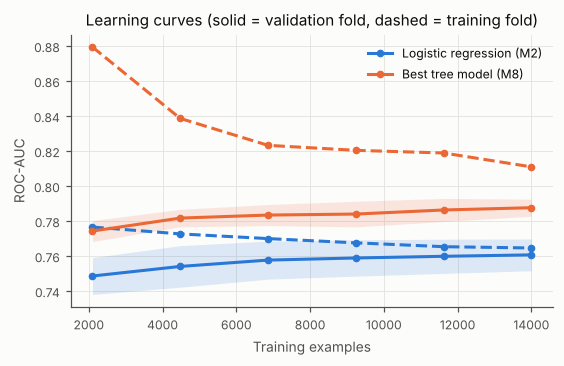

,train_auc@max,cv_auc@max,gap
Logistic regression (M2),0.7647,0.7608,0.0039
Best tree model (M8),0.8110,0.7877,0.0233


In [16]:
sizes = np.linspace(0.15, 1.0, 3 if QUICK else 6)
curves = {}
for label, exp in [("Logistic regression (M2)", "M2"), (f"Best tree model ({BEST_ML})", BEST_ML)]:
    ts, trn, val = learning_curve(clone(MODELS[exp]), X_tr, y_tr, train_sizes=sizes, cv=CV3, scoring="roc_auc",
                                  n_jobs=2, shuffle=True, random_state=SEED)
    curves[label] = (ts, trn.mean(1), trn.std(1), val.mean(1), val.std(1))

fig, ax = plt.subplots(figsize=(5.2, 3.4))
cols = [BLUE, ORANGE]
for (label, (ts, tm, tsd, vm, vsd)), c in zip(curves.items(), cols):
    ax.plot(ts, tm, color=c, ls="--", marker="o", ms=4)
    ax.plot(ts, vm, color=c, ls="-", marker="o", ms=4, label=label)
    ax.fill_between(ts, vm - vsd, vm + vsd, color=c, alpha=0.15, lw=0)
ax.set_xlabel("Training examples"); ax.set_ylabel("ROC-AUC"); ax.set_title("Learning curves (solid = validation fold, dashed = training fold)")
ax.legend(loc="upper right"); fig.tight_layout(); savefig(fig, "fig2_learning_curves_ml.png")
pd.DataFrame({k: {"train_auc@max": v[1][-1], "cv_auc@max": v[3][-1], "gap": v[1][-1] - v[3][-1]} for k, v in curves.items()}).T.round(4)

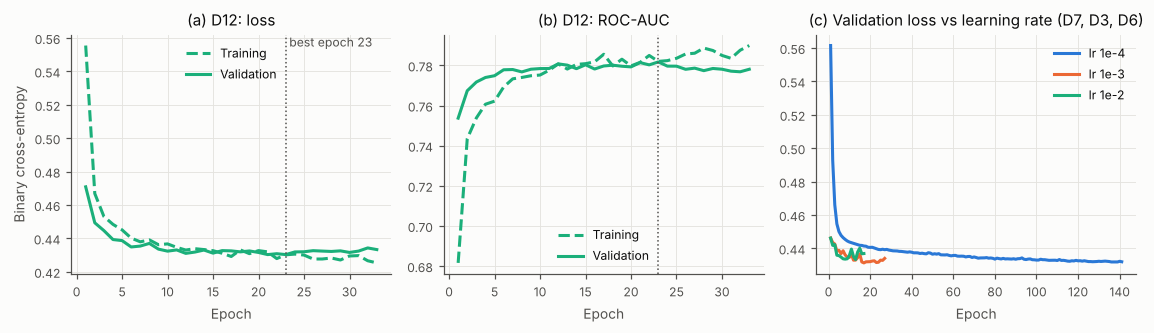

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.1))
h = HISTORIES[BEST_DL]; ep = np.arange(1, len(h["loss"]) + 1); be = int(np.argmax(h["val_auc"])) + 1
ax[0].plot(ep, h["loss"], color=AQUA, ls="--", label="Training"); ax[0].plot(ep, h["val_loss"], color=AQUA, label="Validation")
ax[0].axvline(be, color=MUTED, lw=1, ls=":"); ax[0].text(be, ax[0].get_ylim()[1], f" best epoch {be}", va="top", fontsize=8, color=MUTED)
ax[0].set_title(f"(a) {BEST_DL}: loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Binary cross-entropy"); ax[0].legend()
ax[1].plot(ep, h["auc"], color=AQUA, ls="--", label="Training"); ax[1].plot(ep, h["val_auc"], color=AQUA, label="Validation")
ax[1].axvline(be, color=MUTED, lw=1, ls=":"); ax[1].set_title(f"(b) {BEST_DL}: ROC-AUC"); ax[1].set_xlabel("Epoch"); ax[1].legend()
for exp, lab, c in [("D7", "lr 1e-4", BLUE), ("D3", "lr 1e-3", ORANGE), ("D6", "lr 1e-2", AQUA)]:
    hh = HISTORIES[exp]; ax[2].plot(np.arange(1, len(hh["val_loss"]) + 1), hh["val_loss"], color=c, label=lab)
ax[2].set_title("(c) Validation loss vs learning rate (D7, D3, D6)"); ax[2].set_xlabel("Epoch"); ax[2].legend()
fig.tight_layout(); savefig(fig, "fig3_dl_curves.png")

In [18]:
# ---- final evaluation on the held-out test set (first and only use)
def test_scores(exp):
    if exp.startswith("M"):
        return scores_of(MODELS[exp], X_te)
    fs, kind = MODELS[exp + "_fs"]
    return MODELS[exp].predict(make_ds(DATA[fs]["te"], y_te, kind, 1024, False), verbose=0).ravel()

FINAL = {"LR": "M2", "ML": BEST_ML, "DL": BEST_DL}
S_TE = {k: test_scores(e) for k, e in FINAL.items()}
THR = {k: f1_threshold(y_va, VAL_SCORES[e]) for k, e in FINAL.items()}   # chosen on validation only
boot_rng = np.random.RandomState(SEED); B = 30 if QUICK else 1000
idx = boot_rng.randint(0, len(y_te), size=(B, len(y_te)))
def boot(fn):
    return np.array([fn(i) for i in idx])
rows = []
for k, e in FINAL.items():
    m = metrics_at(y_te, S_TE[k], THR[k])
    aucs = boot(lambda i, s=S_TE[k]: roc_auc_score(y_te[i], s[i]))
    aps = boot(lambda i, s=S_TE[k]: average_precision_score(y_te[i], s[i]))
    rows.append(dict(role=k, exp=e, model=table.set_index("exp").loc[e, "model"], threshold=round(THR[k], 4),
                     auc=m["auc"], auc_lo=np.percentile(aucs, 2.5), auc_hi=np.percentile(aucs, 97.5),
                     ap=m["ap"], ap_lo=np.percentile(aps, 2.5), ap_hi=np.percentile(aps, 97.5),
                     acc=m["acc"], prec=m["prec"], rec=m["rec"], f1=m["f1"]))
test_df = pd.DataFrame(rows).round(4)
diff = boot(lambda i: roc_auc_score(y_te[i], S_TE["DL"][i]) - roc_auc_score(y_te[i], S_TE["ML"][i]))
print(f"DL - ML test AUC difference: {roc_auc_score(y_te, S_TE['DL']) - roc_auc_score(y_te, S_TE['ML']):+.4f}, 95% bootstrap CI [{np.percentile(diff, 2.5):+.4f}, {np.percentile(diff, 97.5):+.4f}]")
test_df.to_csv(RES / "test_metrics.csv", index=False)
test_df

DL - ML test AUC difference: -0.0051, 95% bootstrap CI [-0.0104, -0.0000]


,role,exp,model,threshold,auc,auc_lo,auc_hi,ap,ap_lo,ap_hi,acc,prec,rec,f1
0,LR,M2,Logistic regression,0.2594,0.7502,0.7320,0.7675,0.4967,0.4626,0.5289,0.7676,0.4790,0.5713,0.5211
1,ML,M8,Hist. gradient boosting (tuned),0.2576,0.7830,0.7669,0.7992,0.5573,0.5244,0.5883,0.7791,0.5008,0.5934,0.5432
2,DL,D12,MLP random search,0.3301,0.7779,0.7622,0.7943,0.5523,0.5182,0.5859,0.7871,0.5175,0.5653,0.5403


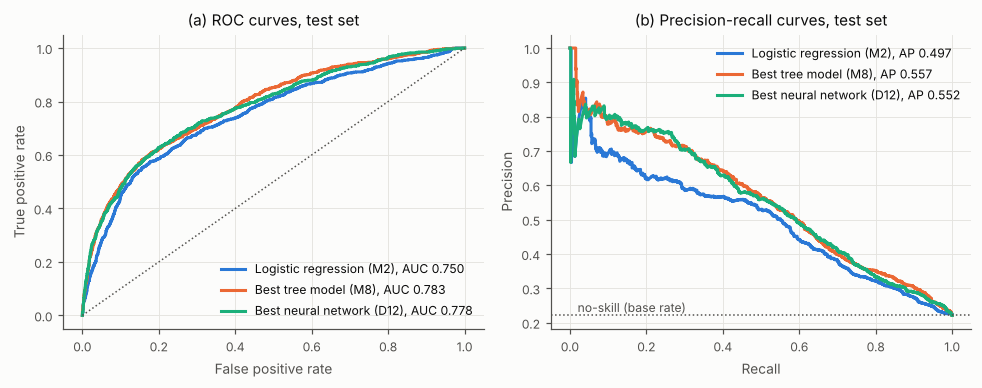

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
labels = {"LR": "Logistic regression (M2)", "ML": f"Best tree model ({BEST_ML})", "DL": f"Best neural network ({BEST_DL})"}
for k in ["LR", "ML", "DL"]:
    fpr, tpr, _ = roc_curve(y_te, S_TE[k]); p_, r_, _ = precision_recall_curve(y_te, S_TE[k])
    auc_ = roc_auc_score(y_te, S_TE[k]); ap_ = average_precision_score(y_te, S_TE[k])
    ax[0].plot(fpr, tpr, color=MODEL_COLOURS[k], label=f"{labels[k]}, AUC {auc_:.3f}")
    ax[1].plot(r_, p_, color=MODEL_COLOURS[k], label=f"{labels[k]}, AP {ap_:.3f}")
ax[0].plot([0, 1], [0, 1], color=MUTED, lw=1, ls=":"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("(a) ROC curves, test set"); ax[0].legend(loc="lower right")
ax[1].axhline(y_te.mean(), color=MUTED, lw=1, ls=":"); ax[1].text(0.02, y_te.mean() + 0.01, "no-skill (base rate)", fontsize=8, color=MUTED)
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("(b) Precision-recall curves, test set"); ax[1].legend(loc="upper right")
fig.tight_layout(); savefig(fig, "fig4_roc_pr.png")

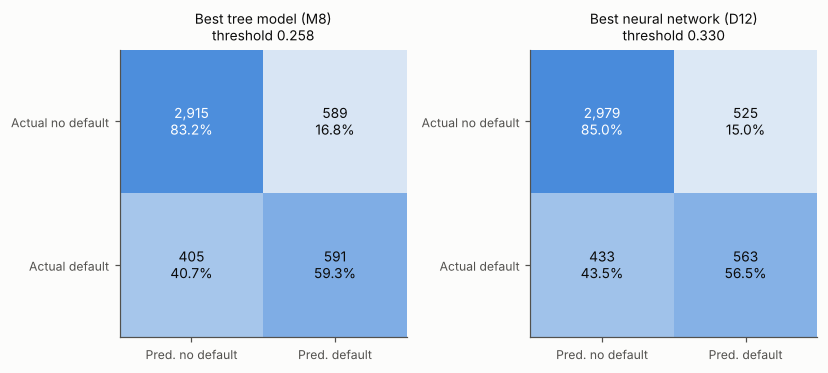

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(7.6, 3.5))
cm_cmap = matplotlib.colors.LinearSegmentedColormap.from_list("blue_ramp", [SURFACE, BLUE])
CMS = {}
for a, k in zip(ax, ["ML", "DL"]):
    cm = confusion_matrix(y_te, (S_TE[k] >= THR[k]).astype(int)); CMS[k] = cm
    norm = cm / cm.sum(1, keepdims=True)
    a.imshow(norm, cmap=cm_cmap, vmin=0, vmax=1); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}\n{norm[i, j]:.1%}", ha="center", va="center", fontsize=9, color=INK if norm[i, j] < 0.6 else "white")
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(["Pred. no default", "Pred. default"]); a.set_yticklabels(["Actual no default", "Actual default"])
    a.set_title(f"{labels[k]}\nthreshold {THR[k]:.3f}", fontsize=9)
fig.tight_layout(); savefig(fig, "fig5_confusion.png")

**Interpretation.** On the held-out test set, tuned gradient boosting (M8) reaches AUC 0.783 (95% bootstrap CI 0.767-0.799) and the selected network (D12) 0.778 (0.762-0.794), against 0.750 for logistic regression. The paired bootstrap difference DL minus ML is -0.005 (95% CI -0.010 to 0.000), so boosting is nominally ahead but the evidence is borderline, not decisive. On validation data the order was reversed (D12 0.7818 against M8 0.7806), and five reseeded runs of the D12 configuration average 0.7798 +/- 0.0006: the seed-42 network is a favourable draw (+0.002, about 3.6 seed standard deviations) and picking the best of 17 trials on validation data inflated its score (winner's curse). Both models improve clearly on logistic regression in average precision (0.557 and 0.552 against 0.497). *Bias and variance.* Logistic regression has a train-validation gap of 0.004 and plateaus at 0.761 (high bias); boosting has a gap of 0.023 and a validation curve still rising slowly at 14,000 examples (moderate variance, more data would help). In Fig. 3 the network's training AUC pulls above validation AUC after about epoch 20 while validation loss flattens and then rises slightly, which early stopping (best epoch 23) handles. *Confusion matrices.* At the F1-optimal thresholds, M8 catches 59.3% of defaulters (591 of 996) at a 16.8% false-positive rate (589 of 3,504); D12 catches 56.5% at 15.0%.

## 9. Error analysis, feature importance and cost-sensitive thresholds

* **Where do errors concentrate?** False-negative and false-positive rates by latest repayment status, credit limit and demographic group
  (test set, validation-chosen thresholds).
* **What drives the prediction?** Permutation importance of the best tree model on the validation set (drop in ROC-AUC when one feature is shuffled).
* **Decision threshold in business terms.** Suppose a missed defaulter costs `r` times as much as a wrongly declined good customer. For each `r` the threshold minimising expected cost on validation is
  applied to the test set and compared with approving everyone. The cost ratios are illustrative assumptions, not estimated from the data.

In [21]:
d_te = prepare(X_te).reset_index(drop=True)
d_te["y"] = y_te
d_te["LIMIT_Q"] = pd.cut(X_te["LIMIT_BAL"].reset_index(drop=True), [-np.inf] + list(X_tr["LIMIT_BAL"].quantile([.25, .5, .75])) + [np.inf],
                         labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
d_te["PAY_GROUP"] = pd.cut(d_te["PAY_1"], [-np.inf, 0, 1, np.inf], labels=["on time / revolving (<=0)", "1 month late", ">=2 months late"])
d_te["SEX_L"] = d_te["SEX"].map({1: "male", 2: "female"})
d_te["EDU_L"] = d_te["EDUCATION"].map({1: "graduate school", 2: "university", 3: "high school", 4: "other"})
rows = []
for k in ["ML", "DL"]:
    pred = (S_TE[k] >= THR[k]).astype(int)
    for gcol in ["PAY_GROUP", "LIMIT_Q", "SEX_L", "EDU_L"]:
        for lvl, idxs in d_te.groupby(gcol, observed=True).groups.items():
            yy, pp = y_te[idxs], pred[idxs]
            rows.append(dict(model=k, group=gcol, level=lvl, n=len(idxs), default_rate=yy.mean(),
                             FNR=((pp == 0) & (yy == 1)).sum() / max((yy == 1).sum(), 1),
                             FPR=((pp == 1) & (yy == 0)).sum() / max((yy == 0).sum(), 1), flagged=pp.mean()))
err = pd.DataFrame(rows).round(3); err.to_csv(RES / "error_analysis.csv", index=False)
both_wrong = ((S_TE["ML"] >= THR["ML"]) != y_te) & ((S_TE["DL"] >= THR["DL"]) != y_te)
print(f"errors shared by both models: {both_wrong.sum()} of {((S_TE['ML'] >= THR['ML']) != y_te).sum()} (ML errors) / {((S_TE['DL'] >= THR['DL']) != y_te).sum()} (DL errors)")
err

errors shared by both models: 862 of 994 (ML errors) / 958 (DL errors)


,model,group,level,n,default_rate,FNR,FPR,flagged
0,ML,PAY_GROUP,on time / revolving (<=0),3468,0.140,0.785,0.069,0.089
1,ML,PAY_GROUP,1 month late,564,0.328,0.135,0.639,0.713
2,ML,PAY_GROUP,>=2 months late,468,0.699,0.000,1.000,1.000
3,ML,LIMIT_Q,Q1 (lowest),1124,0.307,0.290,0.322,0.441
4,ML,LIMIT_Q,Q2,1189,0.240,0.379,0.177,0.283
5,ML,LIMIT_Q,Q3,1081,0.165,0.517,0.118,0.179
6,ML,LIMIT_Q,Q4 (highest),1106,0.170,0.559,0.077,0.139
7,ML,SEX_L,female,2734,0.200,0.398,0.157,0.247
8,ML,SEX_L,male,1766,0.254,0.417,0.186,0.287
9,ML,EDU_L,graduate school,1580,0.203,0.444,0.141,0.225


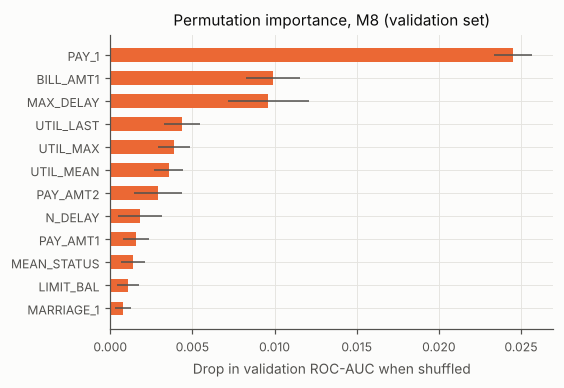

,feature,mean,std
14,PAY_1,0.0245,0.0012
1,BILL_AMT1,0.0099,0.0016
28,MAX_DELAY,0.0096,0.0025
22,UTIL_LAST,0.0044,0.0011
21,UTIL_MAX,0.0039,0.0010
20,UTIL_MEAN,0.0036,0.0009
8,PAY_AMT2,0.0029,0.0015
27,N_DELAY,0.0018,0.0013
7,PAY_AMT1,0.0016,0.0008
29,MEAN_STATUS,0.0014,0.0007


In [22]:
best_pipe = MODELS[BEST_ML]
Xv = best_pipe.named_steps["pre"].transform(X_va)
names = [n.split("__", 1)[1] for n in best_pipe.named_steps["pre"].named_steps["columns"].get_feature_names_out()]
pi = permutation_importance(best_pipe.named_steps["clf"], Xv, y_va, scoring="roc_auc", n_repeats=2 if QUICK else 10, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": names, "mean": pi.importances_mean, "std": pi.importances_std}).sort_values("mean", ascending=False)
imp.to_csv(RES / "permutation_importance.csv", index=False)
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.barh(top.feature, top["mean"], xerr=top["std"], color=ORANGE, height=0.6, error_kw=dict(ecolor=MUTED, lw=1))
ax.set_xlabel("Drop in validation ROC-AUC when shuffled"); ax.set_title(f"Permutation importance, {BEST_ML} (validation set)")
fig.tight_layout(); savefig(fig, "fig6_importance.png")
imp.head(12).round(4)

In [23]:
def exp_cost(y, s, thr, ratio):
    pred = s >= thr
    return (ratio * ((~pred) & (y == 1)).sum() + ((pred) & (y == 0)).sum()) / len(y)

def cost_threshold(y, s, ratio):
    grid = np.unique(np.quantile(s, np.linspace(0.01, 0.99, 300)))
    return float(grid[np.argmin([exp_cost(y, s, t, ratio) for t in grid])])

rows = []
for r in [1, 3, 5, 10]:
    for k in ["ML", "DL"]:
        t = cost_threshold(y_va, VAL_SCORES[FINAL[k]], r)
        pred = S_TE[k] >= t
        c = exp_cost(y_te, S_TE[k], t, r); base = r * y_te.mean()
        rows.append(dict(cost_ratio=r, model=k, threshold=round(t, 3), test_cost_per_applicant=round(c, 4),
                         approve_all_cost=round(base, 4), saving_vs_approve_all=f"{(1 - c / base):.1%}",
                         recall=round(((pred) & (y_te == 1)).sum() / (y_te == 1).sum(), 3),
                         precision=round(((pred) & (y_te == 1)).sum() / max(pred.sum(), 1), 3), declined_share=round(pred.mean(), 3)))
cost_df = pd.DataFrame(rows); cost_df.to_csv(RES / "cost_analysis.csv", index=False); cost_df

,cost_ratio,model,threshold,test_cost_per_applicant,approve_all_cost,saving_vs_approve_all,recall,precision,declined_share
0,1,ML,0.512,0.1804,0.2213,18.5%,0.360,0.672,0.119
1,1,DL,0.464,0.1829,0.2213,17.4%,0.373,0.651,0.127
2,3,ML,0.258,0.4009,0.6640,39.6%,0.593,0.501,0.262
3,3,DL,0.329,0.4049,0.6640,39.0%,0.566,0.517,0.242
4,5,ML,0.137,0.5500,1.1067,50.3%,0.826,0.338,0.541
5,5,DL,0.195,0.5484,1.1067,50.4%,0.720,0.401,0.398
6,10,ML,0.078,0.7087,2.2133,68.0%,0.948,0.261,0.803
7,10,DL,0.077,0.7173,2.2133,67.6%,0.944,0.261,0.802


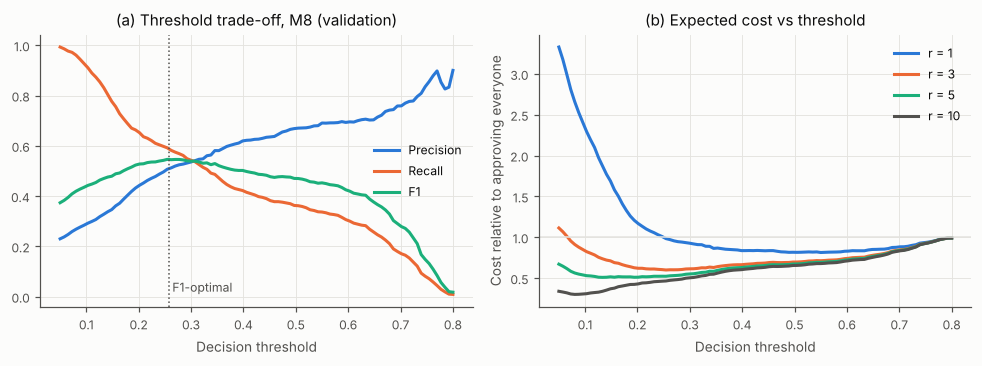

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
s = VAL_SCORES[BEST_ML]; ts = np.linspace(0.05, 0.8, 100)
pr_ = [precision_score(y_va, s >= t, zero_division=0) for t in ts]; rc_ = [recall_score(y_va, s >= t) for t in ts]
f_ = [f1_score(y_va, s >= t) for t in ts]
ax[0].plot(ts, pr_, color=BLUE, label="Precision"); ax[0].plot(ts, rc_, color=ORANGE, label="Recall"); ax[0].plot(ts, f_, color=AQUA, label="F1")
ax[0].axvline(THR["ML"], color=MUTED, ls=":", lw=1); ax[0].text(THR["ML"], 0.02, " F1-optimal", fontsize=8, color=MUTED)
ax[0].set_xlabel("Decision threshold"); ax[0].set_title(f"(a) Threshold trade-off, {BEST_ML} (validation)"); ax[0].legend(loc="center right")
for r, c in [(1, BLUE), (3, ORANGE), (5, AQUA), (10, MUTED)]:
    cost = [exp_cost(y_va, s, t, r) for t in ts]; ax[1].plot(ts, np.array(cost) / (r * y_va.mean()), color=c, label=f"r = {r}")
ax[1].axhline(1, color=GRID, lw=1); ax[1].set_xlabel("Decision threshold"); ax[1].set_ylabel("Cost relative to approving everyone")
ax[1].set_title("(b) Expected cost vs threshold"); ax[1].legend()
fig.tight_layout(); savefig(fig, "fig7_threshold.png")

**Interpretation.** Errors are dominated by repayment recency. Among customers with `PAY_1` <= 0 (3,468 of 4,500; 14.0% default) both models miss most defaulters (false-negative rate 79% for M8, 84% for D12) because nothing in their history yet signals trouble. Among customers already two or more months late (70% default), M8 flags every one and D12 flags 98.7%, so the threshold gives no discrimination there; the models separate defaulters mainly in the middle group (one month late). Both produce more false negatives for high-limit customers (56% in the top quartile for M8, 63% for D12) than for low-limit customers (29-31%), mirroring lower base rates. Sex and education show smaller gaps: M8's false-negative rate is 39.8% for women and 41.7% for men, and its false-positive rate 15.7% and 18.6%. The two models make largely the same mistakes (862 of M8's 994 errors are also among D12's 958), which suggests limited gain from simple ensembling. Permutation importance (Fig. 6) agrees: shuffling the latest repayment status (`PAY_1`) costs 0.0245 AUC, 2.5 times the next feature, and the engineered `MAX_DELAY` and `UTIL_*` features rank in the top six. In the cost analysis, if a missed defaulter costs five times a wrongly declined customer, M8 and D12 cut expected cost per applicant by about 50% relative to approving everyone (0.550 against 1.107) and the best threshold falls to 0.14-0.20; at a ratio of ten the saving is 68%.

## 10. Saving artefacts and conclusions

Saved for the Drive folder: the best traditional model as a complete pipeline (`joblib`, accepts raw columns), the best neural network in Keras
(`.keras` and legacy `.h5`) with its fitted preprocessor and threshold, the experiment table, and a JSON summary of headline numbers.

In [25]:
joblib.dump(MODELS[BEST_ML], MOD / "best_ml_pipeline.joblib")
fs_best, kind_best = MODELS[BEST_DL + "_fs"]
MODELS[BEST_DL].save(MOD / "best_dl_model.keras")
MODELS[BEST_DL].save(MOD / "best_dl_model.h5")
joblib.dump({"preprocessor": PRE[fs_best], "threshold": THR["DL"], "kind": kind_best}, MOD / "best_dl_preprocessor.joblib")

# round-trip check: reload both and confirm identical test scores
ml_loaded = joblib.load(MOD / "best_ml_pipeline.joblib")
assert np.allclose(scores_of(ml_loaded, X_te), S_TE["ML"])
dl_loaded = keras.models.load_model(MOD / "best_dl_model.keras")
s_dl = dl_loaded.predict(make_ds(DATA[fs_best]["te"], y_te, kind_best, 1024, False), verbose=0).ravel()
assert np.allclose(s_dl, S_TE["DL"], atol=1e-5)

summary = dict(best_ml=BEST_ML, best_dl=BEST_DL, thresholds=THR, test=test_df.set_index("role").to_dict("index"),
               dl_seed_mean=float(seed_df.val_auc.mean()), dl_seed_std=float(seed_df.val_auc.std()),
               n_rows=int(len(raw)), n_train=int(len(X_tr)), n_val=int(len(X_va)), n_test=int(len(X_te)),
               n_features_base=int(DATA["base"]["tr"][0].shape[1]), n_features_eng=int(DATA["eng"]["tr"][0].shape[1]),
               n_experiments=int(len(table)), confusion={k: v.tolist() for k, v in CMS.items()})
json.dump(summary, open(RES / "summary.json", "w"), indent=2, default=float)
print("saved:", sorted(p.name for p in MOD.iterdir()))

saved: ['best_dl_model.h5', 'best_dl_model.keras', 'best_dl_preprocessor.joblib', 'best_ml_pipeline.joblib']


## Conclusions

Tuned gradient boosting (test AUC 0.783) and the best tuned MLP (0.778) both clearly beat logistic regression (0.750). The 0.005 gap between them sits at the edge of the bootstrap interval (-0.010 to 0.000) and is smaller than the +0.002 luck the selected network enjoyed on validation data, so the honest summary is that trees are at least as good as networks here, at a fraction of the tuning and training cost. Recent repayment behaviour carries most of the signal. Feature engineering mattered for the linear model (+0.012 AUC) and the network (+0.008) but not for trees, and demographic attributes can be dropped at negligible cost (-0.0002 AUC).

**Limitations.** One 2005 Taiwanese portfolio; one train/validation/test split; cost ratios are assumed rather than estimated; no probability-calibration analysis; the SVM was tuned over three values of C only.

**Future work.** Calibrate probabilities (Platt or isotonic) before using the cost-based thresholds, repeat selection with nested cross-validation, add XGBoost/LightGBM and a boosting-plus-MLP ensemble, use time-ordered validation on a newer portfolio, and test fairness constraints.